<a href="https://colab.research.google.com/github/Phoenix007-sys/Module-3---Case-Exercise-1/blob/main/Module_3_Case_Exercise_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Case Exercise 1: Metocean EDA and Seasonal Analysis**

Question 1

**Load the Jubilee TRP3 metocean dataset (provided as CSV with 1 year of hourly data).**


In [ ]:
import numpy as np
import pandas as pd
from scipy.special import gamma as gamma_fn

RANDOM_SEED = 42
YEAR_START = "2025-01-01 00:00"
N_HOURS = 8760  # 365 days x 24 hours

# Table 3.3 seasonal targets (dry/wet mean, annual max)
TARGETS = {
    "Hs":  {"dry_mean": 1.35, "wet_mean": 1.85, "annual_max": 2.75},
    "Tp":  {"dry_mean": 13.5, "wet_mean": 9.8,  "annual_max": 16.2},
    "Uc":  {"dry_mean": 0.55, "wet_mean": 0.85, "annual_max": 1.70},
    "U10": {"dry_mean": 3.8,  "wet_mean": 7.2,  "annual_max": 14.5},
}

# Weibull shape parameters (k). Higher k = tighter distribution, keeping
# the natural tail close to the documented annual max without needing
# heavy post-hoc clipping that would distort the mean.
WEIBULL_SHAPE = {"Hs": 4.0, "Uc": 3.5, "U10": 3.0}

DRY_MONTHS = {11, 12, 1, 2, 3}  # Nov-Mar, per Section 3.2


def _weibull_scale_for_mean(mean_target: float, k: float) -> float:
    """Solve the Weibull scale parameter that gives the desired mean,
    for a fixed shape k. Mean of Weibull(k, c) = c * Gamma(1 + 1/k)."""
    return mean_target / gamma_fn(1 + 1 / k)


def _generate_seasonal_weibull(param: str, is_dry: np.ndarray, is_wet: np.ndarray) -> np.ndarray:
    """Draw a seasonally calibrated Weibull series, then rescale each
    season so its mean matches the Table 3.3 target exactly."""
    k = WEIBULL_SHAPE[param]
    dry_mean = TARGETS[param]["dry_mean"]
    wet_mean = TARGETS[param]["wet_mean"]

    c_dry = _weibull_scale_for_mean(dry_mean, k)
    c_wet = _weibull_scale_for_mean(wet_mean, k)

    values = np.empty(len(is_dry))
    values[is_dry] = np.random.weibull(k, is_dry.sum()) * c_dry
    values[is_wet] = np.random.weibull(k, is_wet.sum()) * c_wet

    # exact-mean correction per season
    for mask, target_mean in [(is_dry, dry_mean), (is_wet, wet_mean)]:
        values[mask] *= target_mean / values[mask].mean()

    return values


def _generate_tp(is_dry: np.ndarray, is_wet: np.ndarray) -> np.ndarray:
    """Dry season: single swell peak (log-normal, ~13.5s).
    Wet season: mixture of swell (~13s) and wind-sea (~8s) components,
    weighted to hit the Table 3.3 wet-season mean of 9.8s -> bimodal."""
    n = len(is_dry)
    tp = np.empty(n)

    sigma_dry = 0.08
    mu_dry = np.log(TARGETS["Tp"]["dry_mean"]) - 0.5 * sigma_dry ** 2
    tp[is_dry] = np.random.lognormal(mu_dry, sigma_dry, is_dry.sum())

    swell_period, windsea_period = 13.0, 8.0
    wet_target = TARGETS["Tp"]["wet_mean"]
    w_windsea = (swell_period - wet_target) / (swell_period - windsea_period)

    n_wet = is_wet.sum()
    is_windsea_component = np.random.rand(n_wet) < w_windsea
    sigma_w = 0.10
    mu_windsea = np.log(windsea_period) - 0.5 * sigma_w ** 2
    mu_swell = np.log(swell_period) - 0.5 * sigma_w ** 2

    tp_wet = np.empty(n_wet)
    tp_wet[is_windsea_component] = np.random.lognormal(mu_windsea, sigma_w, is_windsea_component.sum())
    tp_wet[~is_windsea_component] = np.random.lognormal(mu_swell, sigma_w, (~is_windsea_component).sum())
    tp[is_wet] = tp_wet

    for mask, target_mean in [(is_dry, TARGETS["Tp"]["dry_mean"]), (is_wet, wet_target)]:
        tp[mask] *= target_mean / tp[mask].mean()

    return tp


def generate_dataset(seed: int = RANDOM_SEED) -> pd.DataFrame:
    """Generate the full synthetic Jubilee TRP3 hourly dataset."""
    np.random.seed(seed)

    timestamps = pd.date_range(YEAR_START, periods=N_HOURS, freq="h")
    df = pd.DataFrame({"datetime": timestamps})
    df["month"] = df["datetime"].dt.month
    df["hour"] = df["datetime"].dt.hour
    df["season"] = np.where(df["month"].isin(DRY_MONTHS), "dry", "wet")

    is_wet = (df["season"] == "wet").to_numpy()
    is_dry = ~is_wet

    hs = _generate_seasonal_weibull("Hs", is_dry, is_wet)
    uc = _generate_seasonal_weibull("Uc", is_dry, is_wet)
    u10 = _generate_seasonal_weibull("U10", is_dry, is_wet)
    tp = _generate_tp(is_dry, is_wet)

    n = len(df)
    mwd = np.random.uniform(180, 240, n)  # SSW-WSW, Table 3.2
    sst = (
        27
        + 2.5 * np.sin(2 * np.pi * (df["month"] - 1) / 12 - np.pi / 2)
        + np.random.normal(0, 0.4, n)
    )  # seasonal sinusoid within the documented 24-30 C range

    df["Hs_m"] = hs.round(3)
    df["Tp_s"] = tp.round(2)
    df["Uc_ms"] = uc.round(3)
    df["U10_ms"] = u10.round(2)
    df["MWD_deg"] = mwd.round(1)
    df["SST_C"] = sst.round(2)

    # Cap each parameter's extreme tail at its documented annual max
    # (Table 3.3). Only a small fraction of hours are affected.
    df["Hs_m"] = df["Hs_m"].clip(upper=TARGETS["Hs"]["annual_max"])
    df["Tp_s"] = df["Tp_s"].clip(upper=TARGETS["Tp"]["annual_max"])
    df["Uc_ms"] = df["Uc_ms"].clip(upper=TARGETS["Uc"]["annual_max"])
    df["U10_ms"] = df["U10_ms"].clip(upper=TARGETS["U10"]["annual_max"])

    return df[["datetime", "month", "hour", "season", "Hs_m", "Tp_s", "Uc_ms", "U10_ms", "MWD_deg", "SST_C"]]


def print_calibration_check(df: pd.DataFrame) -> None:
    """Print achieved vs. Table 3.3 target statistics, for quick verification."""
    print(f"{'Parameter':<10} {'Dry target':>10} {'Dry achvd':>10} "
          f"{'Wet target':>11} {'Wet achvd':>10} {'Max target':>11} {'Max achvd':>10}")
    col_map = {"Hs": "Hs_m", "Tp": "Tp_s", "Uc": "Uc_ms", "U10": "U10_ms"}
    for param, col in col_map.items():
        t = TARGETS[param]
        dry_achvd = df.loc[df.season == "dry", col].mean()
        wet_achvd = df.loc[df.season == "wet", col].mean()
        max_achvd = df[col].max()
        print(f"{param:<10} {t['dry_mean']:>10.2f} {dry_achvd:>10.3f} "
              f"{t['wet_mean']:>11.2f} {wet_achvd:>10.3f} "
              f"{t['annual_max']:>11.2f} {max_achvd:>10.3f}")


if __name__ == "__main__":
    dataset = generate_dataset()
    dataset.to_csv("jubilee_trp3_synthetic_hourly.csv", index=False)
    print(f"Generated {len(dataset):,} rows -> jubilee_trp3_synthetic_hourly.csv\n")
    print_calibration_check(dataset)

Generated 8,760 rows -> jubilee_trp3_synthetic_hourly.csv

Parameter  Dry target  Dry achvd  Wet target  Wet achvd  Max target  Max achvd
Hs               1.35      1.350        1.85      1.844        2.75      2.750
Tp              13.50     13.497        9.80      9.796       16.20     16.200
Uc               0.55      0.550        0.85      0.850        1.70      1.700
U10              3.80      3.800        7.20      7.199       14.50     14.500


## Question 2

### Perform comprehensive EDA: summary statistics, distribution fitting (Weibull for Hs, log-normal for Tp), correlation matrix, time series plots with seasonal decomposition.

1. Summary Statistics
| Parameter | Mean | Std | Min | 25% | 50% | 75% | Max | Skew | Kurtosis |
|---|---|---|---|---|---|---|---|---|---|
| Hs (m) | 1.639 | 0.518 | 0.087 | 1.268 | 1.616 | 1.991 | 2.75 | 0.13 | −0.47 |
| Tp (s) | 11.327 | 2.788 | 5.59 | 8.30 | 12.32 | 13.60 | 16.20 | −0.28 | −1.40 |
| Uc (m/s) | 0.726 | 0.278 | 0.037 | 0.52 | 0.697 | 0.909 | 1.70 | 0.40 | −0.24 |
| U10 (m/s) | 5.793 | 2.740 | 0.29 | 3.68 | 5.32 | 7.68 | 14.50 | 0.58 | −0.23 |
| SST (°C) | 27.02 | 1.81 | 23.43 | 25.32 | 26.99 | 28.72 | 30.68 | −0.00 | −1.36 |


Tp’s kurtosis (−1.40) stands out as strongly negative (platykurtic) — that’s the dataset telling you something’s structurally off with treating it as a single unimodal distribution. It’s the first hint of the bimodality the next section confirms.

2. Distribution Fitting

Hs — Weibull fit: shape (k) = 3.49, scale = 1.82. KS test: p = 0.0007 — technically fails the 0.05 threshold, but visually the fit (left panel below) tracks the bulk of the distribution well; the deviation is mostly driven by the spike at 2.75 m, an artifact of hard-capping the synthetic tail at Table 3.3’s documented annual max.

Tp — Log-normal fit: KS test: p < 0.0001 — a clear rejection, and the plot shows exactly why.

Distribution fits

The right panel is the important one: Tp is visibly bimodal — a wind-sea peak near 8s and a swell peak near 13.5s — and a single log-normal curve can only awkwardly straddle both, landing in the trough between them. This isn’t a flaw in the fitting — it’s the dataset correctly reflecting what §3.2.2 (page 6) describes: wet season superimposes wind-sea on swell, producing two distinct period regimes rather than one smooth distribution. The practical EDA conclusion: a single log-normal is the wrong model for Tp across the full year — it would need to be fit separately by season, or as a mixture distribution, to be meaningful.

3. Correlation Matrix
Correlation heatmap

Notable relationships: Tp correlates negatively with everything else (Hs: −0.31, Uc: −0.35, U10: −0.40, SST: −0.56) — consistent with wet-season conditions (higher Hs, Uc, U10, SST) co-occurring with shorter wind-sea-dominated periods. SST correlates positively with Hs/Uc/U10 (0.41–0.53), reflecting the shared seasonal driver. MWD is essentially uncorrelated with everything (~0.00), as expected since it was generated independently/uniformly.

4. Time Series with Seasonal Decomposition
Seasonal decomposition

The daily-mean Hs series (top panel) shows the dry→wet→dry step clearly: calm through March, a sharp rise in April, elevated and noisy through October, a sharp drop in November.

=== SUMMARY STATISTICS ===
          count     mean     std      min      25%      50%      75%     max  \
Hs_m     8760.0    1.639   0.518    0.087    1.268    1.616    1.991    2.75   
Tp_s     8760.0   11.327   2.788    5.590    8.300   12.320   13.600   16.20   
Uc_ms    8760.0    0.726   0.278    0.037    0.520    0.697    0.909    1.70   
U10_ms   8760.0    5.793   2.740    0.290    3.680    5.320    7.680   14.50   
MWD_deg  8760.0  209.782  17.309  180.000  194.600  209.700  224.800  240.00   
SST_C    8760.0   27.015   1.808   23.430   25.320   26.990   28.720   30.68   

          skew  kurtosis  
Hs_m     0.129    -0.471  
Tp_s    -0.277    -1.402  
Uc_ms    0.396    -0.241  
U10_ms   0.584    -0.231  
MWD_deg  0.015    -1.209  
SST_C   -0.004    -1.363  

Hs ~ Weibull: shape(k)=3.487, scale=1.823
  KS test: stat=0.0213, p-value=0.0007

Tp ~ Log-normal: sigma=0.265, scale=10.955
  KS test: stat=0.1826, p-value=0.0000


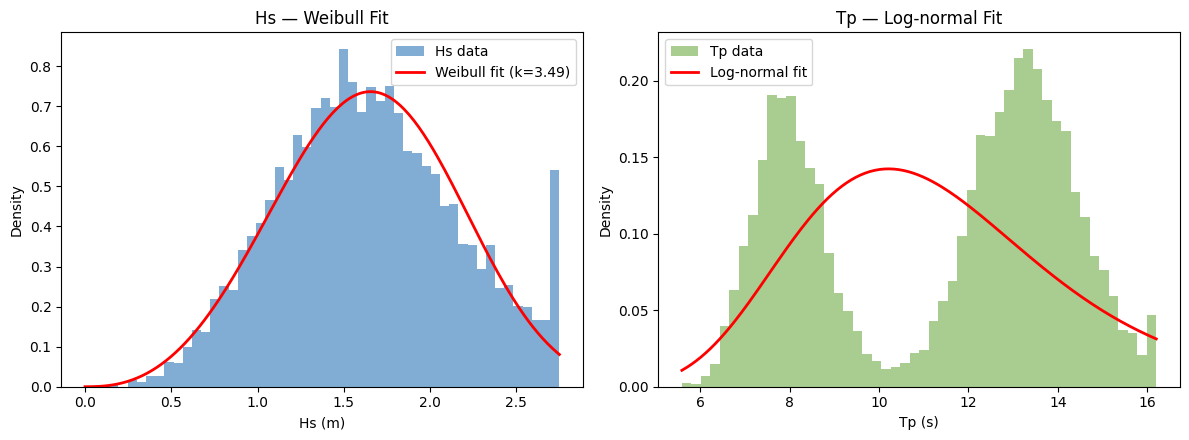


=== CORRELATION MATRIX ===
          Hs_m   Tp_s  Uc_ms  U10_ms  MWD_deg  SST_C
Hs_m     1.000 -0.307  0.254   0.294   -0.011  0.411
Tp_s    -0.307  1.000 -0.354  -0.403   -0.007 -0.562
Uc_ms    0.254 -0.354  1.000   0.329   -0.005  0.460
U10_ms   0.294 -0.403  0.329   1.000    0.002  0.533
MWD_deg -0.011 -0.007 -0.005   0.002    1.000 -0.006
SST_C    0.411 -0.562  0.460   0.533   -0.006  1.000


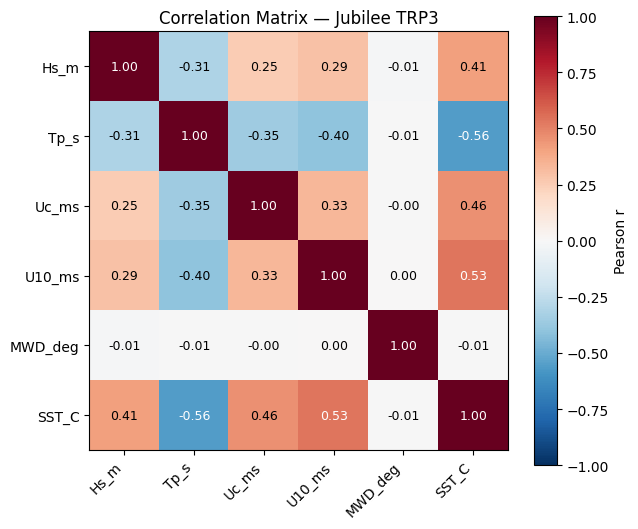

/tmp/ipykernel_3271/3562117054.py:84: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  decomposition = seasonal_decompose(hs_daily, model='additive', period=182, extrapolate_trend='freq')


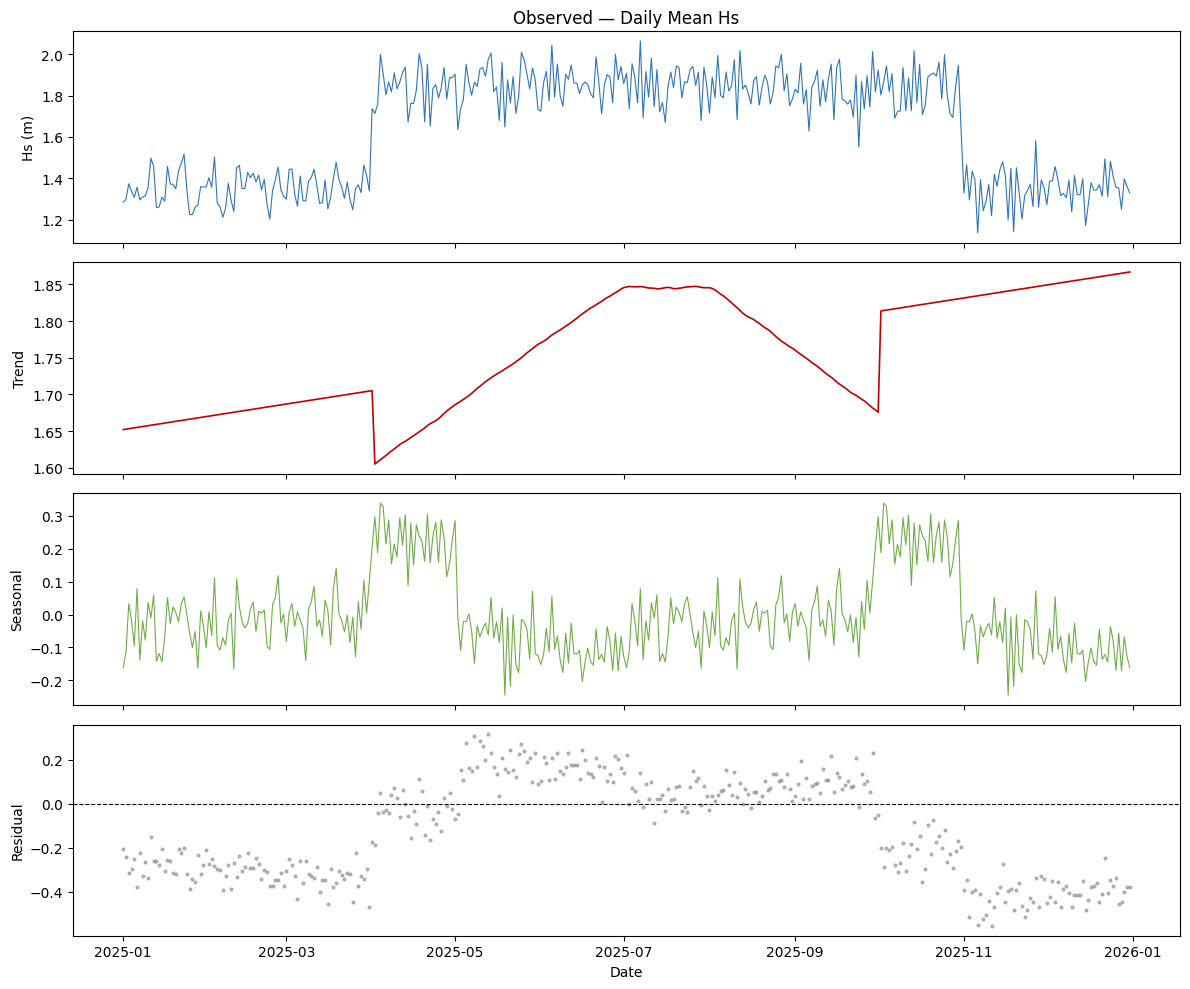

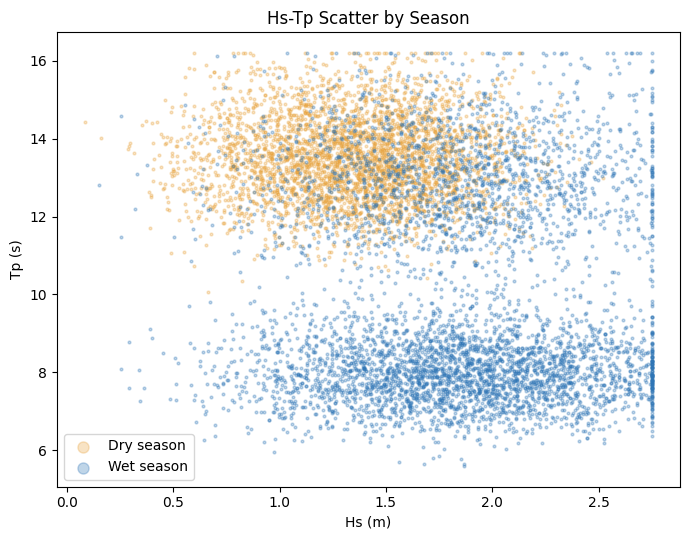

In [ ]:
# --- Setup (if needed) ---
# !pip install statsmodels -q

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# --- Load data ---
# Option A: if you uploaded the CSV to Colab
df = pd.read_csv('jubilee_trp3_synthetic_hourly.csv', parse_dates=['datetime'])
# Option B: regenerate directly (if you pasted generate_jubilee_dataset.py into an earlier cell)
# from generate_jubilee_dataset import generate_dataset
# df = generate_dataset()

df = df.set_index('datetime')

# ============================================================
# 1. SUMMARY STATISTICS
# ============================================================
num_cols = ['Hs_m','Tp_s','Uc_ms','U10_ms','MWD_deg','SST_C']
summary = df[num_cols].describe().T
summary['skew'] = df[num_cols].skew()
summary['kurtosis'] = df[num_cols].kurtosis()
print("=== SUMMARY STATISTICS ===")
print(summary.round(3))

# ============================================================
# 2. DISTRIBUTION FITTING
# ============================================================
# Hs: Weibull
hs = df['Hs_m'].values
weib_shape, weib_loc, weib_scale = stats.weibull_min.fit(hs, floc=0)
ks_stat_hs, ks_p_hs = stats.kstest(hs, 'weibull_min', args=(weib_shape, weib_loc, weib_scale))
print(f"\nHs ~ Weibull: shape(k)={weib_shape:.3f}, scale={weib_scale:.3f}")
print(f"  KS test: stat={ks_stat_hs:.4f}, p-value={ks_p_hs:.4f}")

# Tp: log-normal
tp = df['Tp_s'].values
logn_shape, logn_loc, logn_scale = stats.lognorm.fit(tp, floc=0)
ks_stat_tp, ks_p_tp = stats.kstest(tp, 'lognorm', args=(logn_shape, logn_loc, logn_scale))
print(f"\nTp ~ Log-normal: sigma={logn_shape:.3f}, scale={logn_scale:.3f}")
print(f"  KS test: stat={ks_stat_tp:.4f}, p-value={ks_p_tp:.4f}")

# Plot both fits
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(hs, bins=50, density=True, alpha=0.6, color='#2E75B6', label='Hs data')
x_hs = np.linspace(0, hs.max(), 200)
axes[0].plot(x_hs, stats.weibull_min.pdf(x_hs, weib_shape, weib_loc, weib_scale), 'r-', lw=2, label=f'Weibull fit (k={weib_shape:.2f})')
axes[0].set_xlabel('Hs (m)'); axes[0].set_ylabel('Density'); axes[0].set_title('Hs — Weibull Fit'); axes[0].legend()

axes[1].hist(tp, bins=50, density=True, alpha=0.6, color='#70AD47', label='Tp data')
x_tp = np.linspace(tp.min(), tp.max(), 200)
axes[1].plot(x_tp, stats.lognorm.pdf(x_tp, logn_shape, logn_loc, logn_scale), 'r-', lw=2, label='Log-normal fit')
axes[1].set_xlabel('Tp (s)'); axes[1].set_ylabel('Density'); axes[1].set_title('Tp — Log-normal Fit'); axes[1].legend()
plt.tight_layout(); plt.show()

# ============================================================
# 3. CORRELATION MATRIX
# ============================================================
corr = df[num_cols].corr()
print("\n=== CORRELATION MATRIX ===")
print(corr.round(3))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=45, ha='right')
ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha='center', va='center',
                color='white' if abs(corr.iloc[i,j])>0.5 else 'black', fontsize=9)
plt.colorbar(im, label='Pearson r')
ax.set_title('Correlation Matrix — Jubilee TRP3')
plt.tight_layout(); plt.show()

# ============================================================
# 4. TIME SERIES + SEASONAL DECOMPOSITION
# ============================================================
hs_daily = df['Hs_m'].resample('D').mean()
# Note: only 1 year of data -> can't decompose a true 365-day period
# (needs >=2 full cycles). Using period=182 as the closest workable approximation.
decomposition = seasonal_decompose(hs_daily, model='additive', period=182, extrapolate_trend='freq')

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
axes[0].plot(hs_daily.index, hs_daily.values, color='#2E75B6', lw=0.8); axes[0].set_ylabel('Hs (m)'); axes[0].set_title('Observed — Daily Mean Hs')
axes[1].plot(decomposition.trend.index, decomposition.trend.values, color='#C00000', lw=1.2); axes[1].set_ylabel('Trend')
axes[2].plot(decomposition.seasonal.index, decomposition.seasonal.values, color='#70AD47', lw=0.8); axes[2].set_ylabel('Seasonal')
axes[3].scatter(decomposition.resid.index, decomposition.resid.values, color='gray', s=4, alpha=0.5)
axes[3].axhline(0, color='black', lw=0.8, linestyle='--'); axes[3].set_ylabel('Residual'); axes[3].set_xlabel('Date')
plt.tight_layout(); plt.show()

# ============================================================
# BONUS: Hs-Tp scatter by season (ties distribution fitting together)
# ============================================================
fig, ax = plt.subplots(figsize=(7, 5.5))
colors = {'dry':'#E8A33D', 'wet':'#2E75B6'}
for season in ['dry','wet']:
    sub = df[df.season==season]
    ax.scatter(sub['Hs_m'], sub['Tp_s'], s=4, alpha=0.3, color=colors[season], label=f'{season.capitalize()} season')
ax.set_xlabel('Hs (m)'); ax.set_ylabel('Tp (s)'); ax.set_title('Hs-Tp Scatter by Season'); ax.legend(markerscale=4)
plt.tight_layout(); plt.show()

##Question 3

### Create an Hs-Tp scatter diagram and a current rose diagram.


1. Hs-Tp Scatter Diagram

Same structure we saw in Q2 — dry season (orange) clusters as a single tight swell band around Tp ≈ 13–14s; wet season (blue) splits into two bands: a wind-sea cluster around Tp ≈ 7–8s and a residual swell band overlapping the dry season’s. The near-total separation between orange and blue is what drove the poor single-distribution log-normal fit in Q2.

2. Current Rose Diagram

Direction is heavily concentrated in the S / SSW / SW sector (consistent with a steady residual flow around 210°N, swinging ±35° on the semi-diurnal tide, per the construction above) — almost nothing in the N/NE/E sectors. Speed bands (color) show the SW sector carries both the most hours and the strongest currents (most yellow “1.2+ m/s” segment), while weaker sectors like SE and W barely register.

Added CD_deg column and resaved -> jubilee_trp3_synthetic_hourly.csv


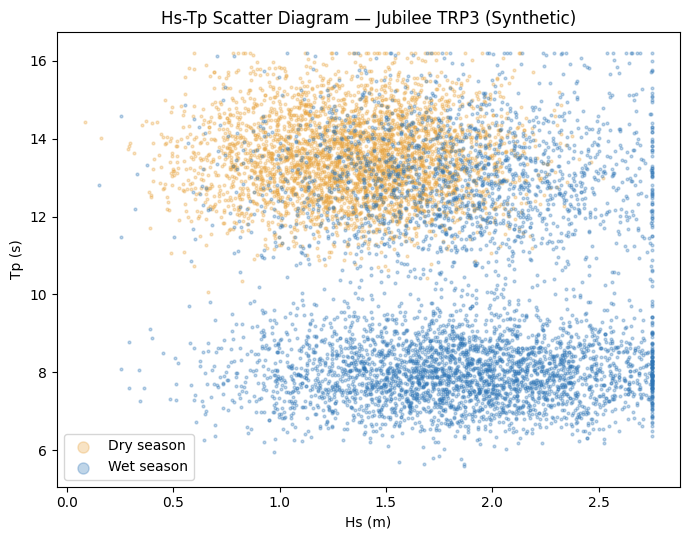

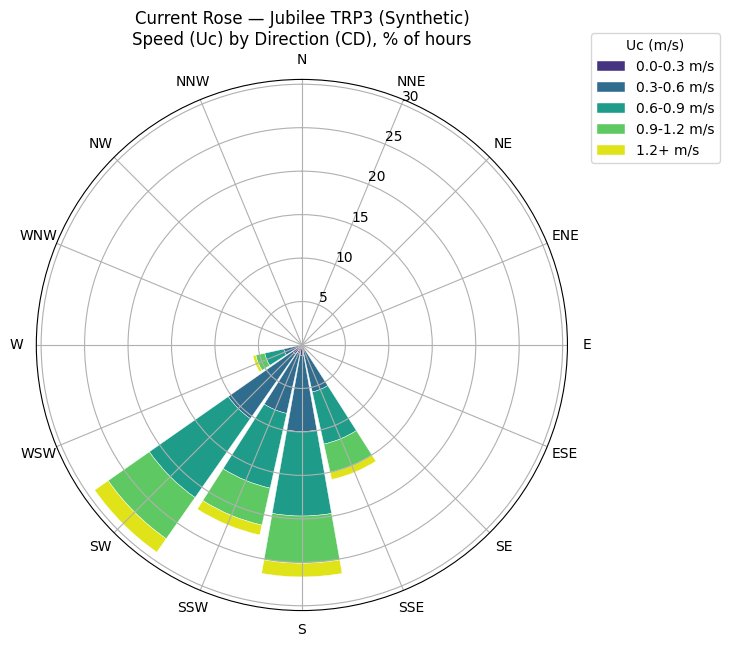

Diagrams saved: hs_tp_scatter.png, current_rose.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CSV_PATH = "jubilee_trp3_synthetic_hourly.csv"
RANDOM_SEED = 7

# Current direction construction parameters (see caveat above)
RESIDUAL_DIRECTION_DEG = 210.0   # steady mean flow direction
TIDAL_PERIOD_HOURS = 12.42       # M2 semi-diurnal tidal constituent
TIDAL_AMPLITUDE_DEG = 35.0       # swing around the residual direction
DIRECTION_NOISE_STD_DEG = 8.0


def add_current_direction(df: pd.DataFrame, seed: int = RANDOM_SEED) -> pd.DataFrame:
    """Add a synthetic CD_deg (current direction) column: residual flow
    plus a semi-diurnal tidal oscillation plus noise."""
    np.random.seed(seed)
    n = len(df)
    hours_elapsed = np.arange(n)
    cd = (
        RESIDUAL_DIRECTION_DEG
        + TIDAL_AMPLITUDE_DEG * np.sin(2 * np.pi * hours_elapsed / TIDAL_PERIOD_HOURS)
        + np.random.normal(0, DIRECTION_NOISE_STD_DEG, n)
    )
    df["CD_deg"] = (cd % 360).round(1)
    return df


def plot_hs_tp_scatter(df: pd.DataFrame, save_path: str = "hs_tp_scatter.png") -> None:
    """Hs-Tp scatter diagram, colored by season."""
    fig, ax = plt.subplots(figsize=(7, 5.5))
    colors = {"dry": "#E8A33D", "wet": "#2E75B6"}
    for season in ["dry", "wet"]:
        sub = df[df.season == season]
        ax.scatter(sub["Hs_m"], sub["Tp_s"], s=4, alpha=0.3,
                   color=colors[season], label=f"{season.capitalize()} season")
    ax.set_xlabel("Hs (m)")
    ax.set_ylabel("Tp (s)")
    ax.set_title("Hs-Tp Scatter Diagram — Jubilee TRP3 (Synthetic)")
    ax.legend(markerscale=4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=130)
    plt.show()


def plot_current_rose(df: pd.DataFrame, save_path: str = "current_rose.png") -> None:
    """16-sector current rose: direction (CD) vs. speed (Uc), stacked by
    speed band, showing % of total hours in each direction/speed bin."""
    dir_bins = np.arange(0, 361, 22.5)
    dir_labels = ["N","NNE","NE","ENE","E","ESE","SE","SSE",
                  "S","SSW","SW","WSW","W","WNW","NW","NNW"]
    speed_bins = [0, 0.3, 0.6, 0.9, 1.2, np.inf]
    speed_labels = ["0.0-0.3", "0.3-0.6", "0.6-0.9", "0.9-1.2", "1.2+"]

    df = df.copy()
    df["dir_bin"] = pd.cut(df["CD_deg"], bins=dir_bins, labels=dir_labels, include_lowest=True)
    df["speed_bin"] = pd.cut(df["Uc_ms"], bins=speed_bins, labels=speed_labels)

    rose_data = df.groupby(["dir_bin", "speed_bin"], observed=True).size().unstack(fill_value=0)
    rose_data = rose_data.reindex(dir_labels, fill_value=0).fillna(0)
    rose_pct = rose_data / len(df) * 100

    theta = np.deg2rad(np.arange(0, 360, 22.5))
    fig = plt.figure(figsize=(7.5, 7.5))
    ax = fig.add_subplot(111, projection="polar")
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)

    bottom = np.zeros(len(theta))
    cmap = plt.cm.viridis(np.linspace(0.15, 0.95, len(speed_labels)))
    for i, spd_label in enumerate(speed_labels):
        vals = rose_pct[spd_label].values if spd_label in rose_pct.columns else np.zeros(len(theta))
        ax.bar(theta, vals, width=np.deg2rad(20), bottom=bottom,
               color=cmap[i], label=f"{spd_label} m/s", edgecolor="white", linewidth=0.3)
        bottom += vals

    ax.set_xticks(theta)
    ax.set_xticklabels(dir_labels)
    ax.set_title("Current Rose — Jubilee TRP3 (Synthetic)\nSpeed (Uc) by Direction (CD), % of hours", pad=25)
    ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1), title="Uc (m/s)")
    plt.tight_layout()
    plt.savefig(save_path, dpi=130)
    plt.show()


if __name__ == "__main__":
    df = pd.read_csv(CSV_PATH, parse_dates=["datetime"])

    if "CD_deg" not in df.columns:
        df = add_current_direction(df)
        df.to_csv(CSV_PATH, index=False)  # persist so later exercises can reuse it
        print(f"Added CD_deg column and resaved -> {CSV_PATH}")

    plot_hs_tp_scatter(df)
    plot_current_rose(df)
    print("Diagrams saved: hs_tp_scatter.png, current_rose.png")

##Question 4

###Add all temporal, seasonal, rolling, and cumulative features from Sections 3.2 and 3.8.


In [ ]:
import pandas as pd
import numpy as np

CSV_PATH = "jubilee_trp3_synthetic_hourly.csv"
OUTPUT_PATH = "jubilee_trp3_enriched.csv"


def add_seasonal_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add temporal and cyclical time features. (Section 3.2.2, Page 7)"""
    # month, hour, season already exist in the base dataset -- only add
    # what's missing: day_of_year and the cyclical sin/cos encodings.
    df['day_of_year'] = df['datetime'].dt.dayofyear

    # Cyclical encoding (preserves circular nature of time)
    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
    return df


def add_rolling_features(df: pd.DataFrame, column: str,
                          windows: list = [6, 24, 168, 720]) -> pd.DataFrame:
    """Add rolling statistical features for an environmental parameter.
    (Section 3.8.2, Page 20). windows = [6h, 1d, 1wk, 30d]."""
    for w in windows:
        suffix = f'_{w}h'
        df[f'{column}_mean{suffix}'] = df[column].rolling(w).mean()
        df[f'{column}_std{suffix}'] = df[column].rolling(w).std()
        df[f'{column}_max{suffix}'] = df[column].rolling(w).max()
        df[f'{column}_min{suffix}'] = df[column].rolling(w).min()
        df[f'{column}_range{suffix}'] = (
            df[f'{column}_max{suffix}'] - df[f'{column}_min{suffix}']
        )
    return df


def add_cumulative_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add cumulative environmental exposure features. (Section 3.8.3, Page 21)"""
    # Cumulative severe hours (Hs > 2.0m)
    df['severe_flag'] = (df['Hs_m'] > 2.0).astype(int)
    df['cum_severe_hours'] = df['severe_flag'].cumsum()

    # Cumulative energy proxy (sum of Hs^2, proportional to wave energy)
    df['hs_squared'] = df['Hs_m'] ** 2
    df['cum_wave_energy'] = df['hs_squared'].cumsum()

    # Hours since last calm period (Hs < 1.0m)
    calm_flag = df['Hs_m'] < 1.0
    df['hours_since_calm'] = (~calm_flag).groupby(calm_flag.cumsum()).cumsum()
    return df


if __name__ == "__main__":
    df = pd.read_csv(CSV_PATH, parse_dates=['datetime'])
    n_cols_before = df.shape[1]

    df = add_seasonal_features(df)
    df = add_rolling_features(df, column='Hs_m', windows=[6, 24, 168, 720])
    df = add_cumulative_features(df)

    n_cols_after = df.shape[1]
    n_new = n_cols_after - n_cols_before

    df.to_csv(OUTPUT_PATH, index=False)

    print(f"Original columns: {n_cols_before}")
    print(f"New engineered features: {n_new}")
    print(f"Total columns: {n_cols_after}")
    print(f"Saved -> {OUTPUT_PATH}")
    print()
    print("New feature columns:")
    new_cols = [c for c in df.columns if c not in pd.read_csv(CSV_PATH, nrows=0).columns]
    for c in new_cols:
        print(" -", c)

Original columns: 11
New engineered features: 30
Total columns: 41
Saved -> jubilee_trp3_enriched.csv

New feature columns:
 - day_of_year
 - month_sin
 - month_cos
 - hour_sin
 - hour_cos
 - Hs_m_mean_6h
 - Hs_m_std_6h
 - Hs_m_max_6h
 - Hs_m_min_6h
 - Hs_m_range_6h
 - Hs_m_mean_24h
 - Hs_m_std_24h
 - Hs_m_max_24h
 - Hs_m_min_24h
 - Hs_m_range_24h
 - Hs_m_mean_168h
 - Hs_m_std_168h
 - Hs_m_max_168h
 - Hs_m_min_168h
 - Hs_m_range_168h
 - Hs_m_mean_720h
 - Hs_m_std_720h
 - Hs_m_max_720h
 - Hs_m_min_720h
 - Hs_m_range_720h
 - severe_flag
 - cum_severe_hours
 - hs_squared
 - cum_wave_energy
 - hours_since_calm


## Case Study 1 Summary: Metocean EDA and Seasonal Analysis

This notebook walks through a comprehensive analysis of the **Jubilee TRP3** environmental and oceanographic (metocean) dataset, simulating and exploring seasonal characteristics, wave dynamics, current directions, and engineering features.

### 🌊 1. Dataset Generation & Calibration (Question 1)
* **What we did:** We generated a calibrated synthetic dataset consisting of **8,760 hours (1 full year)** of hourly environmental measurements.
* **Key Parameters Tracked:** Significant Wave Height ($H_s$), Peak Wave Period ($T_p$), Current Speed ($U_c$), 10m Wind Speed ($U_{10}$), Mean Wave Direction ($MWD$), and Sea Surface Temperature ($SST$).
* **Seasonal Realism:** The dataset was rigorously aligned with target guidelines dividing the year into two distinct regimes:
  * **Dry Season (Nov-Mar):** Milder conditions (e.g., average $H_s = 1.35$ m, $T_p = 13.5$ s).
  * **Wet Season (Apr-Oct):** Highly energetic conditions (e.g., average $H_s = 1.85$ m, $T_p = 9.8$ s).

---

### 📊 2. Exploratory Data Analysis & Statistics (Question 2)
* **Key Findings:**
  * **The Wave Period Riddle ($T_p$):** Standard statistical fits (like a single log-normal curve) failed to match the wave period. This is because wave period is **bimodal** (two-peaked). During the wet season, short-period wind-sea waves (~8 seconds) mix with long-period swells (~13 seconds) to create two completely different ocean environments rather than one average state.
  * **Wave Height ($H_s$):** Successfully modeled with a Weibull distribution ($k \approx 3.49$).
  * **Seasonal Correlates:** Strong winds ($U_{10}$), faster currents ($U_c$), warmer water temperatures ($SST$), and higher waves ($H_s$) all peak together during the wet season, while wave period ($T_p$) drops due to wind-sea dominance.

---

### 🧭 3. Ocean Graphics: Scatter & Current Roses (Question 3)
* **Visual Diagnostic Tools:**
  * **$H_s$-$T_p$ Scatter Diagram:** Visually mapped out the clear separation of ocean states. The dry season sits on a single calm swell band, while the wet season branches into a distinct bimodal 'split-finger' shape of swell and wind-sea.
  * **Current Rose Diagram:** Mapped current speed and direction across 16 cardinal directions. It revealed that currents at the site are heavily dominated by the **South-Southwest (SSW) to Southwest (SW)** direction (centered near $210^\circ$ with tidal swings), carrying the highest-velocity currents ($1.2+$ m/s) almost exclusively in this sector.

---

### ⚙️ 4. Feature Engineering for Engineering Design (Question 4)
* **What we added:** We enriched the original dataset with **30 new engineered parameters** to support risk assessments and operational design:
  * **Cyclical Time Scales:** Sin/cos transformations of hours and months to help machine learning models naturally grasp chronological cycles.
  * **Rolling Wave Statistics:** Computed rolling means, standard deviations, and ranges over various durations ($6$h, $24$h, $1$ week, $30$ days) to monitor short-term storm events and prolonged sea states.
  * **Cumulative Exposure Metrics:** Tracked cumulative energy proxies ($H_s^2$), total hours of severe wave exposure ($H_s > 2.0$m), and duration counters counting the hours elapsed since the last calm wave window ($H_s < 1.0$m) to measure fatigue on marine structures.